In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. DATASET
# ==========================================
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']].values
y = data[['harga']].values

# Normalisasi X dan y menggunakan scaler terpisah
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

# Split data dengan random_state tetap
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# ==========================================
# 2. FUNGSI TRAINING MODEL
# ==========================================
def train_model(learning_rate):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    # Model
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(1,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1)
    ])

    # Optimizer dengan learning rate yang diuji
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss='mse'
    )

    # Training
    history = model.fit(
        X_train,
        y_train,
        epochs=100,
        batch_size=1,
        verbose=0
    )

    # Evaluasi pada data testing
    test_loss = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    train_loss = history.history['loss'][-1]

    print(f"\nLearning Rate : {learning_rate}")
    print(f"Train Loss    : {train_loss:.6f}")
    print(f"Test Loss     : {test_loss:.6f}")

    return {
        'Learning Rate': learning_rate,
        'Train Loss': train_loss,
        'Test Loss': test_loss
    }


# ==========================================
# 3. PERBANDINGAN LEARNING RATE
# ==========================================
learning_rates = [0.1, 0.01, 0.001]
results = []

for lr in learning_rates:
    results.append(train_model(lr))

# ==========================================
# 4. TABEL PERBANDINGAN
# ==========================================
df = pd.DataFrame(results)

print("\n=== HASIL PERBANDINGAN LEARNING RATE ===")
print(df.to_string(index=False))

# Learning rate dengan test loss terendah
best = df.loc[df['Test Loss'].idxmin()]

print("\nLearning rate dengan Test Loss terendah:")
print(f"Learning Rate: {best['Learning Rate']}")
print(f"Test Loss    : {best['Test Loss']:.6f}")



Learning Rate : 0.1
Train Loss    : 0.155352
Test Loss     : 0.087434

Learning Rate : 0.01
Train Loss    : 0.001283
Test Loss     : 0.078329

Learning Rate : 0.001
Train Loss    : 0.380349
Test Loss     : 0.242351

=== HASIL PERBANDINGAN LEARNING RATE ===
 Learning Rate  Train Loss  Test Loss
         0.100    0.155352   0.087434
         0.010    0.001283   0.078329
         0.001    0.380349   0.242351

Learning rate dengan Test Loss terendah:
Learning Rate: 0.01
Test Loss    : 0.078329


Jumlah data: 20640
Jumlah fitur: 8


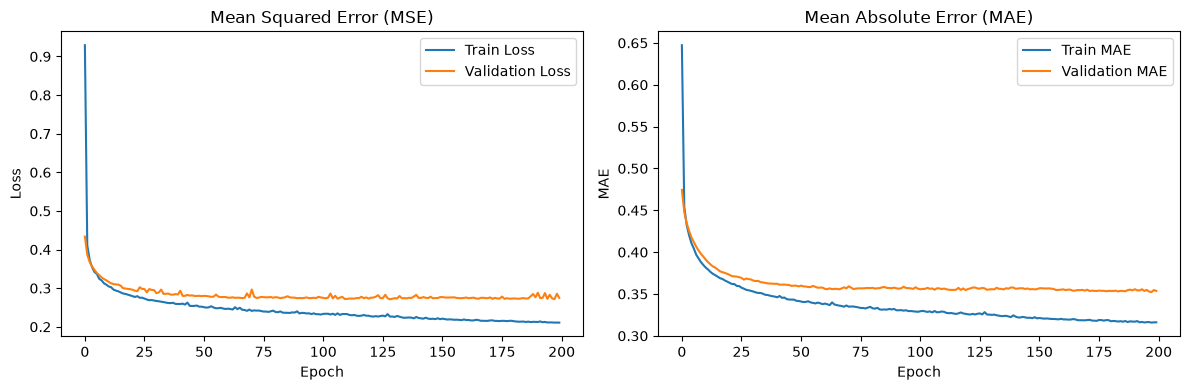

RMSE: 0.5244
MAE : 0.3536


In [4]:
# MLP Regresi (Keras)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# 1. Load dataset
data = fetch_california_housing()

X = data.data
y = data.target

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])

# 2. Preprocessing
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

# 3. Build model
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

# 4. Train
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    verbose=0
)

# 5. Plot loss dan MAE
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Mean Squared Error (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Mean Absolute Error (MAE)')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()

# 6. Evaluasi model
pred = model.predict(X_val, verbose=0).flatten()

rmse = np.sqrt(mean_squared_error(y_val, pred))
mae = np.mean(np.abs(y_val - pred))

print(f"RMSE: {rmse:.4f}")
print(f"MAE : {mae:.4f}")